# HW6. Общий разбор прогона

Ядро **Python (hw6 driver)**. Run All читает последний `results/*/results.json` и рисует сравнение, по которому потом пишется README.

Короткий прогон: 120 запросов при 120 RPM, прогрев 8. Кривой по другим RPM и поиска SLA в этих данных нет.

In [2]:
!pip install matplotlib

  Using cached contourpy-1.4.0-cp312-cp312-manylinux_2_27_x86_64.manylinux_2_28_x86_64.whl.metadata (3.8 kB)
  Using cached cycler-0.12.1-py3-none-any.whl.metadata (3.8 kB)
  Using cached fonttools-4.68.0-cp312-cp312-manylinux2014_x86_64.manylinux_2_17_x86_64.whl.metadata (139 kB)
  Using cached kiwisolver-1.5.1-cp312-cp312-manylinux2014_x86_64.manylinux_2_17_x86_64.whl.metadata (5.2 kB)
  Using cached pillow-13.0.0-cp312-cp312-manylinux_2_27_x86_64.manylinux_2_28_x86_64.whl.metadata (9.1 kB)
  Using cached pyparsing-3.3.3-py3-none-any.whl.metadata (5.9 kB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.9/9.9 MB 19.8 MB/s  0:00:00 eta 0:00:01
Using cached contourpy-1.4.0-cp312-cp312-manylinux_2_27_x86_64.manylinux_2_28_x86_64.whl (383 kB)
Using cached cycler-0.12.1-py3-none-any.whl (8.3 kB)
Using cached fonttools-4.68.0-cp312-cp312-manylinux2014_x86_64.manylinux_2_17_x86_64.whl (5.4 MB)
Using cached kiwisolver-1.5.1-cp312-cp312-manylinux2014_x86_64.manylinux_2_17_x86_64.whl (1.5 MB)
   

In [3]:
from pathlib import Path
import json
import matplotlib.pyplot as plt

root = Path('.').resolve()
runs = sorted(p for p in (root / 'results').iterdir() if (p / 'results.json').is_file())
run = runs[-1]
rows = json.loads((run / 'results.json').read_text())
meta = json.loads((run / 'environment.json').read_text())
summary = json.loads((run / 'summary.json').read_text()) if (run / 'summary.json').is_file() else {}
order = ['baseline', 'prefill_2048', 'prefill_4096_seqs_32', 'baseline_ngram3', 'baseline_ngram5']
fixed = [r for r in rows if r.get('phase') == 'fixed' and r.get('status') == 'ok']
fixed.sort(key=lambda r: order.index(r['config']) if r['config'] in order else 99)
print(run)
print('profile:', meta.get('profile'), 'запросов:', meta.get('bench_requests'), 'прогрев:', meta.get('warmup_requests'))
print('конфигов:', len(fixed))


/home/edu/amsafin/HSE-Avito/LLM/hw6/results/20261119-232509-302829
profile: short+2 запросов: 120 прогрев: 8
конфигов: 5


## Ускорение при 120 RPM

Mean E2E, P90 и ускорение к baseline. Рядом средняя длина ответа: если она сильно разъехалась, разницу нельзя списывать только на настройки vLLM.

In [4]:
headers = ['config', 'mean_e2e_s', 'p90_e2e_s', 'speedup_vs_baseline', 'mean_output_tokens', 'errors', 'status']
print(' | '.join(headers))
print(' | '.join('---' for _ in headers))
for row in fixed:
    values = []
    for key in headers:
        value = row.get(key)
        if isinstance(value, float):
            value = f'{value:.3f}'
        values.append(str(value))
    print(' | '.join(values))


config | mean_e2e_s | p90_e2e_s | speedup_vs_baseline | mean_output_tokens | errors | status
--- | --- | --- | --- | --- | --- | ---
baseline | 6.254 | 7.927 | 1.000 | 422.092 | 0 | ok
prefill_2048 | 6.245 | 7.937 | 1.001 | 421.183 | 0 | ok
prefill_4096_seqs_32 | 6.207 | 7.914 | 1.007 | 418.883 | 0 | ok
baseline_ngram3 | 7.556 | 10.401 | 0.828 | 425.225 | 0 | ok
baseline_ngram5 | 7.333 | 10.205 | 0.853 | 423.058 | 0 | ok


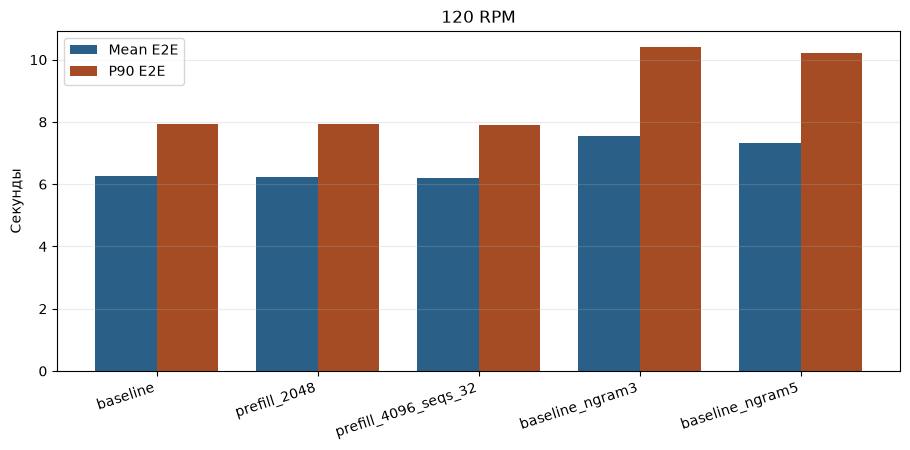

In [5]:
labels = [row['config'] for row in fixed]
means = [row['mean_e2e_s'] for row in fixed]
p90s = [row['p90_e2e_s'] for row in fixed]
x = list(range(len(labels)))
width = 0.38
fig, ax = plt.subplots(figsize=(9.2, 4.6))
ax.bar([i - width / 2 for i in x], means, width=width, color='#2a6088', label='Mean E2E')
ax.bar([i + width / 2 for i in x], p90s, width=width, color='#a54c25', label='P90 E2E')
ax.set_xticks(x, labels, rotation=18, ha='right')
ax.set_ylabel('Секунды')
ax.set_title('120 RPM')
ax.grid(axis='y', alpha=0.25)
ax.legend()
fig.tight_layout()
fig.savefig(run / 'comparison_latency.png', dpi=140)
plt.show()


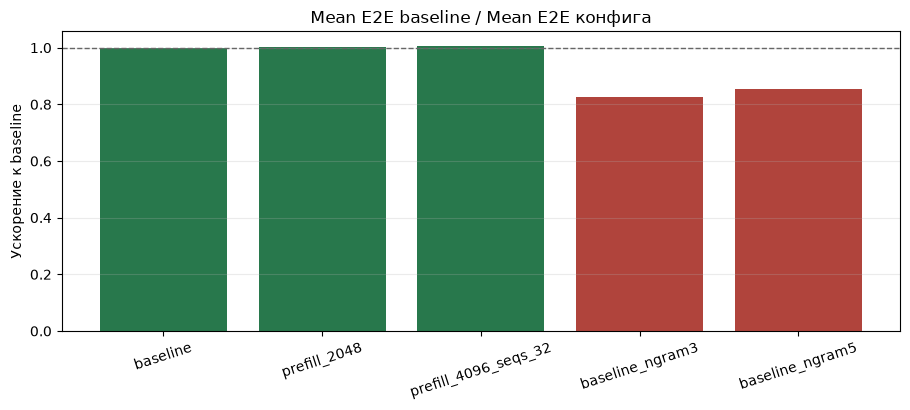

In [6]:
speed = [row['speedup_vs_baseline'] for row in fixed]
colors = ['#28784c' if value >= 1 else '#b0443c' for value in speed]
fig, ax = plt.subplots(figsize=(9.2, 4.2))
ax.bar(labels, speed, color=colors)
ax.axhline(1, color='#666666', linestyle='--', linewidth=1)
ax.set_ylabel('Ускорение к baseline')
ax.set_title('Mean E2E baseline / Mean E2E конфига')
ax.tick_params(axis='x', rotation=18)
ax.grid(axis='y', alpha=0.25)
fig.tight_layout()
fig.savefig(run / 'comparison_speedup.png', dpi=140)
plt.show()


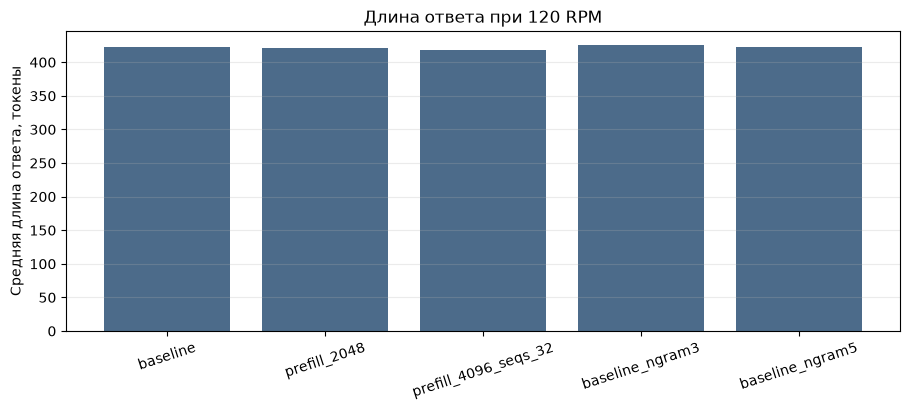

In [7]:
tokens = [row.get('mean_output_tokens') for row in fixed]
fig, ax = plt.subplots(figsize=(9.2, 4.2))
ax.bar(labels, tokens, color='#4c6b8a')
ax.set_ylabel('Средняя длина ответа, токены')
ax.set_title('Длина ответа при 120 RPM')
ax.tick_params(axis='x', rotation=18)
ax.grid(axis='y', alpha=0.25)
fig.tight_layout()
fig.savefig(run / 'comparison_tokens.png', dpi=140)
plt.show()


## P90 и спекулятивное декодирование

Точки есть только там, где замер реально делался. Пустые RPM остаются пропусками.

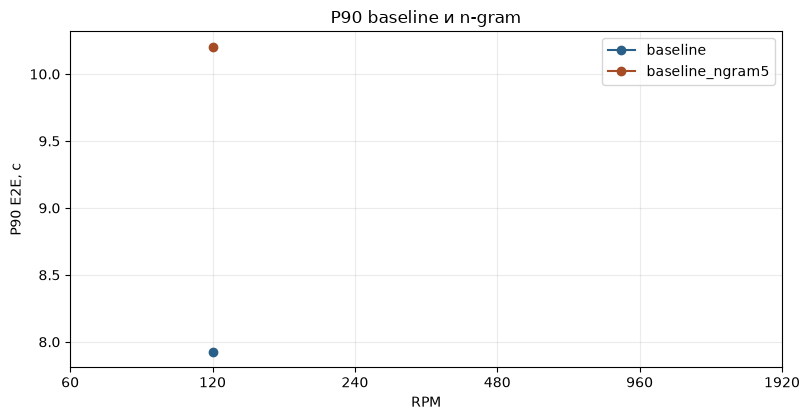

первый RPM, где n-gram хуже: {'rpm': 120, 'baseline_p90_s': 7.9266367, 'ngram_p90_s': 10.2049821011, 'delta_s': 2.2783454011}


In [8]:
points = summary.get('spec_points') or []
spec_name = summary.get('speculative_config') or 'n-gram'
rates = [point['rpm'] for point in points]
baseline = [point['baseline_p90_s'] if point['baseline_p90_s'] is not None else float('nan') for point in points]
ngram = [point['ngram_p90_s'] if point['ngram_p90_s'] is not None else float('nan') for point in points]
fig, ax = plt.subplots(figsize=(8.2, 4.3))
if rates:
    ax.plot(rates, baseline, marker='o', color='#2a6088', label='baseline')
    ax.plot(rates, ngram, marker='o', color='#a54c25', label=spec_name)
    ax.set_xscale('log', base=2)
    ax.set_xticks(rates, [str(rpm) for rpm in rates])
ax.set_xlabel('RPM')
ax.set_ylabel('P90 E2E, с')
ax.set_title('P90 baseline и n-gram')
ax.grid(alpha=0.25)
ax.legend()
fig.tight_layout()
fig.savefig(run / 'spec_p90.png', dpi=140)
plt.show()
print('первый RPM, где n-gram хуже:', summary.get('first_spec_worse'))


## SLA

Если нагрузочного этапа не было, график пустой. Это не граница SLA, а отсутствие замера.

In [9]:
capacity = [row for row in rows if row.get('phase') == 'capacity']
print('capacity_status:', summary.get('capacity_status'))
print('точек SLA:', len(capacity))
if capacity:
    fig, ax = plt.subplots(figsize=(8.2, 4.3))
    ax.plot([row['rpm'] for row in capacity], [row.get('p90_e2e_s') for row in capacity], color='#707b84')
    ax.axhline(meta.get('sla_p90_s', 15), linestyle='--', color='#666666', label='SLA')
    ax.set_xlabel('RPM')
    ax.set_ylabel('P90 E2E, с')
    ax.legend()
    fig.tight_layout()
    fig.savefig(run / 'capacity_p90.png', dpi=140)
    plt.show()


capacity_status: not_started
точек SLA: 0
